Reprodução didática da Aula 2: problema inverso de Poisson com Gauss-Newton.

Dependências: numpy, matplotlib.
Execução: python gauss_newton_poisson.py

In [24]:
import numpy as np
import matplotlib.pyplot as plt

DEFINIÇÃO DO PROBLEMA

In [25]:
L = 5.0
N = 20                         # número total de nós, incluindo os extremos
X = np.linspace(0.0, L, N)
H = X[1] - X[0]
XI = X[1:-1]                 # nós internos: 18 incógnitas
U_ESQ = 1.0
U_DIR = 11.0 * np.exp(5.0)
P_VERDADEIRO = np.array([np.cbrt(2.0), np.cbrt(5.0)])
P_INICIAL = np.array([2.0, 3.0])

DISCRETIZAÇÃO: A u_interno = b(p)
    u''(x_i) ≈ (u_{i-1} - 2u_i + u_{i+1}) / h²
    Logo: 2u_i - u_{i-1} - u_{i+1} = -h² g(x_i,p)

In [26]:
M = N - 2 # numero de icognitas
A = 2.0 * np.eye(M) - np.eye(M, k=1) - np.eye(M, k=-1) # construção da matriz tridiagonal que será sempre ela nesse método


def fonte(x, p):
    """g(x;a,b) = [a³ x + b³] exp(x)."""
    a, b = p
    return (a**3 * x + b**3) * np.exp(x)


def lado_direito(p):
    """Inclui o termo fonte e as condições de Dirichlet."""
    rhs = -(H**2) * fonte(XI, p)
    rhs[0] += U_ESQ
    rhs[-1] += U_DIR
    return rhs


def resolver_direto(p):
    """Resolve o sistema linear de Poisson para parâmetros p=(a,b)."""
    u_interno = np.linalg.solve(A, lado_direito(p))
    return np.concatenate(([U_ESQ], u_interno, [U_DIR]))


OBSERVAÇÕES SINTÉTICAS (mesma malha e simulador da inversão)

In [27]:
U_OBS = resolver_direto(P_VERDADEIRO)
OBS_INTERNAS = U_OBS[1:-1]


def residuos(p):
    """r(p) = u_obs - u_pred(p), apenas nos nós internos."""
    return OBS_INTERNAS - resolver_direto(p)[1:-1]


def objetivo(p):
    """f(p) = (1/2) r(p)^T r(p)."""
    r = residuos(p)
    return 0.5 * (r @ r)

JACOBIANO ANALÍTICO POR SENSIBILIDADES
    A u(p) = b(p) => A (du/dp_j) = db/dp_j
    J = dr/dp = -du/dp (observações fixas)


In [28]:
def jacobiano(p):
    a, b = p
    # Derivadas da fonte: dg/da = a²*x*exp(x), dg/db = b²*exp(x)
    dg_da = 3 * a**2 * XI * np.exp(XI)
    dg_db = 3 * b**2 * np.exp(XI)
    # b(p) = -h² g(p) + termos fixos de contorno
    db_dp = -(H**2) * np.column_stack((dg_da, dg_db))
    du_dp = np.linalg.solve(A, db_dp)
    return -du_dp

GAUSS-NEWTON COM BACKTRACKING (CONDIÇÃO DE ARMIJO)
    (J^T J) d = -J^T r
    p_novo = p + alpha*d

In [29]:
def gauss_newton(p0, tolerancia=1e-8, max_iter=100,
                 alpha_inicial=1.0, rho=0.5, c1=1e-4):
    p = np.asarray(p0, dtype=float).copy()
    historico = []
    print(f"{'iter':>4} {'a':>13} {'b':>13} {'f(p)':>15} {'||grad||':>13} {'alpha':>10} {'reduções':>9}")
    print('-' * 90)

    for k in range(max_iter + 1):
        r = residuos(p)
        J = jacobiano(p)
        f = 0.5 * (r @ r)
        grad = J.T @ r
        norma_grad = np.linalg.norm(grad)
        registro = dict(iteracao=k, a=p[0], b=p[1], f=f,
                        norma_grad=norma_grad, alpha=np.nan, reducoes=0)
        historico.append(registro)

        if norma_grad <= tolerancia:
            print(f"{k:4d} {p[0]:13.8f} {p[1]:13.8f} {f:15.6e} {norma_grad:13.6e} {'-':>10} {'-':>9}")
            print('Convergência: norma do gradiente abaixo da tolerância.')
            break
        if k == max_iter:
            print('Limite máximo de iterações atingido.')
            break

        H_gn = J.T @ J
        # Resolve o sistema normal sem formar inversa explicitamente.
        # Jacobiano sem posto completo => H_gn singular.
        try:
            d = np.linalg.solve(H_gn, -grad)
        except np.linalg.LinAlgError:
            print('Falha: J^T J singular (possível perda de identificabilidade).')
            break

        derivada_direcional = grad @ d
        if derivada_direcional >= 0:
            print('Falha: direção não é de descida.')
            break

        alpha = alpha_inicial
        reducoes = 0
        while objetivo(p + alpha * d) > f + c1 * alpha * derivada_direcional:
            alpha *= rho
            reducoes += 1
            if alpha < 1e-14:
                print('Falha: busca linear não encontrou passo aceitável.')
                return p, historico

        registro['alpha'] = alpha
        registro['reducoes'] = reducoes
        print(f"{k:4d} {p[0]:13.8f} {p[1]:13.8f} {f:15.6e} {norma_grad:13.6e} {alpha:10.5f} {reducoes:9d}")
        p = p + alpha * d

    return p, historico

6. EXECUÇÃO, COMPARAÇÃO E GRÁFICOS

Parâmetros verdadeiros: [1.25992105 1.70997595]
Parâmetros iniciais:    [2. 3.]
Nós totais: 20 | nós internos: 18 | h: 0.2631578947368421
Erro de discretização e resíduos nulos não são a mesma coisa.

iter             a             b            f(p)      ||grad||      alpha  reduções
------------------------------------------------------------------------------------------
   0    2.00000000    3.00000000    4.484966e+07  1.047305e+08    1.00000         0
   1    1.50000000    2.18518519    2.544470e+06  1.381141e+07    1.00000         0
   2    1.29629630    1.80582776    5.530284e+04  1.487953e+06    1.00000         0
   3    1.26093222    1.71497366    8.884523e+01  5.583108e+04    1.00000         0
   4    1.25992186    1.70999050    4.740994e-04  1.286012e+02    1.00000         0
   5    1.25992105    1.70997595    2.840048e-14  9.951082e-04    1.00000         0
   6    1.25992105    1.70997595    1.260304e-27  1.093959e-10          -         -
Convergência: norma do gradiente aba

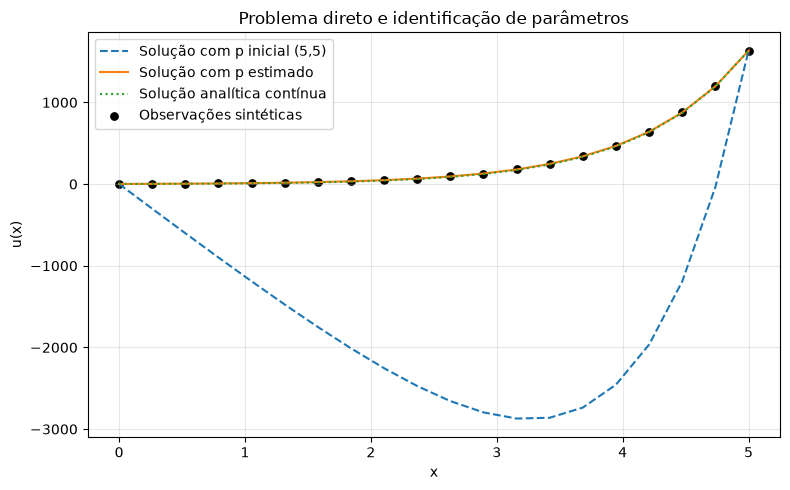

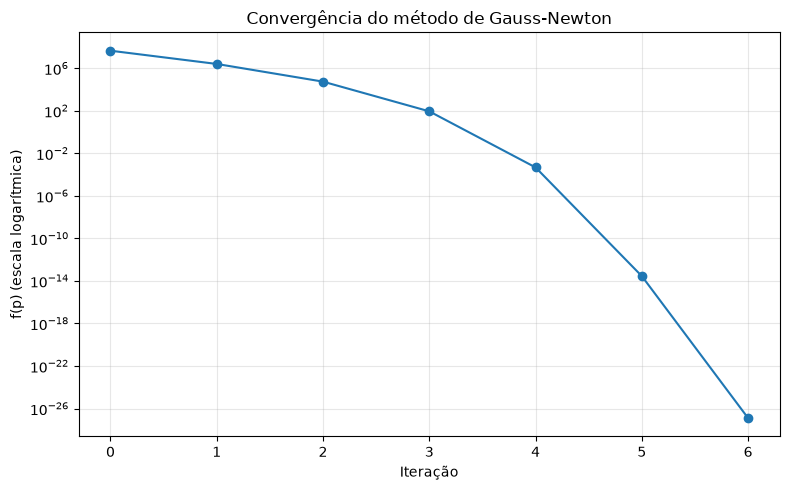

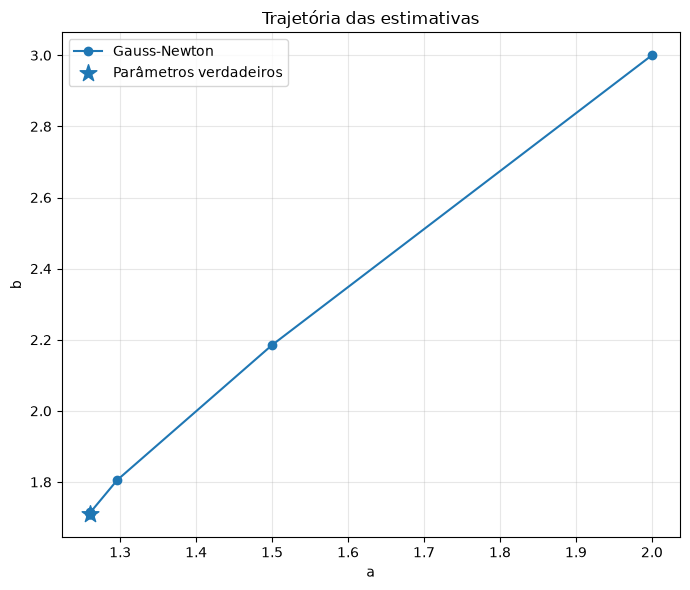

In [30]:
print('Parâmetros verdadeiros:', P_VERDADEIRO)
print('Parâmetros iniciais:   ', P_INICIAL)
print('Nós totais:', N, '| nós internos:', M, '| h:', H)
print('Erro de discretização e resíduos nulos não são a mesma coisa.\n')

p_est, hist = gauss_newton(P_INICIAL)
u_ini = resolver_direto(P_INICIAL)
u_est = resolver_direto(p_est)
u_analitica = (2 * X + 1) * np.exp(X)

print('\nParâmetros estimados: ', p_est)
print('Parâmetros verdadeiros:', P_VERDADEIRO)
print('Erro nos parâmetros:  ', np.linalg.norm(p_est - P_VERDADEIRO))
print('Valor final da função objetivo:', objetivo(p_est))
print('Erro relativo da discretização (norma 2, vs. solução analítica):',
        np.linalg.norm(U_OBS - u_analitica) / np.linalg.norm(u_analitica))

# Figura 1: solução direta, observações e ajuste
plt.figure(figsize=(8, 5))
plt.plot(X, u_ini, '--', label='Solução com p inicial (5,5)')
plt.plot(X, u_est, '-', label='Solução com p estimado')
plt.plot(X, u_analitica, ':', label='Solução analítica contínua')
plt.scatter(X, U_OBS, s=28, color='black', label='Observações sintéticas')
plt.xlabel('x')
plt.ylabel('u(x)')
plt.title('Problema direto e identificação de parâmetros')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('poisson_solucoes.png', dpi=160)

# Figura 2: decaimento da função objetivo
iteracoes = [h['iteracao'] for h in hist]
valores = [max(h['f'], 1e-30) for h in hist]
plt.figure(figsize=(8, 5))
plt.semilogy(iteracoes, valores, 'o-')
plt.xlabel('Iteração')
plt.ylabel('f(p) (escala logarítmica)')
plt.title('Convergência do método de Gauss-Newton')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('poisson_convergencia.png', dpi=160)

# Figura 3: trajetória no espaço de parâmetros
plt.figure(figsize=(7, 6))
plt.plot([h['a'] for h in hist], [h['b'] for h in hist], 'o-', label='Gauss-Newton')
plt.scatter(*P_VERDADEIRO, marker='*', s=160, label='Parâmetros verdadeiros')
plt.xlabel('a')
plt.ylabel('b')
plt.title('Trajetória das estimativas')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('poisson_trajetoria.png', dpi=160)
plt.show()